# Figure S4 — SEM standard reproducibility

This notebook reads concentrations and preferred reference compositions from the `SEM` sheet in `Dechert_S2_Standards.xlsx`. It embeds recovered source-workbook/session provenance for the 204 measurements because those identifiers were omitted from S2. A run means source workbook plus its explicitly recorded session label. Session assignments use source labels, surrounding blocks, and Annika’s confirmed same-workbook groupings; calendar dates are not invented.

Session means are unweighted arithmetic means of available measurements of each standard and oxide. Error bars show between-measurement sample SD (ddof=1), not standard error or propagated individual analytical uncertainty. With one measurement, the mean is shown without an SD bar. Missing values remain missing; no oxide normalization is applied. TDI rows retain time-zero Na2O and 85 s values for other oxides, as already supplied in S2. Spot, TDI and linescan analyses are kept as separate groups to avoid pooling unlike protocols.

Public reproduction: Python 3.11, NumPy, pandas, Matplotlib, openpyxl, IPython, and Jupyter. Edit `DATA_DIRECTORY` below. The shared publication setup is shown first; the Figure S4-specific work begins at the clearly marked heading. Exports are PDF, editable SVG, and a 300 dpi PNG preview. No lab-average comparisons are included.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from IPython.display import display

# Public users: edit DATA_DIRECTORY to your supplemental-data folder.
DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
# Optional: set explicitly if Jupyter starts outside the notebook folder.
NOTEBOOK_DIRECTORY = None
FIGURE_FOLDER = "Figure_S04_SEM_Standard_Reproducibility"
NOTEBOOK_FILENAME = "Plotting_Figure_S04_SEM_Standard_Reproducibility_V2.ipynb"
if NOTEBOOK_DIRECTORY is None:
    here = Path.cwd().resolve()
    candidates = [here, here / FIGURE_FOLDER]
    NOTEBOOK_DIR = next((p for p in candidates if (p / NOTEBOOK_FILENAME).is_file()), None)
    if NOTEBOOK_DIR is None:
        raise FileNotFoundError("Set NOTEBOOK_DIRECTORY to the folder containing this notebook.")
else:
    NOTEBOOK_DIR = Path(NOTEBOOK_DIRECTORY).expanduser().resolve()
WORKBOOK_PATHS = {
    'S1': Path(DATA_DIRECTORY).expanduser() / 'Dechert_S1_AllData.xlsx',
    'S2': Path(DATA_DIRECTORY).expanduser() / 'Dechert_S2_Standards.xlsx',
    'S3': Path(DATA_DIRECTORY).expanduser() / 'Dechert_S3_Compilations.xlsx',
}
for supplement, workbook_path in WORKBOOK_PATHS.items():
    if not workbook_path.is_file():
        raise FileNotFoundError(f'{supplement}: required workbook not found: {workbook_path}')
SOURCE_WORKBOOK = WORKBOOK_PATHS['S2']
OUTPUT_DIR = NOTEBOOK_DIR / f"{FIGURE_FOLDER}_V2_Final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_STEM = "Figure_S04_SEM_Standard_Reproducibility_V2"
PNG_DPI = 300
FIGURE_SIZE_IN = (7.25, 7.55)

print(f"Source workbook: {SOURCE_WORKBOOK}")
print(f"Output directory: {OUTPUT_DIR}")


Source workbook: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20/Dechert_S2_Standards.xlsx
Output directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S04_SEM_Standard_Reproducibility/Figure_S04_SEM_Standard_Reproducibility_V2_Final


## Shared Science Advances figure setup

This cell reproduces the applicable constants from `00_Setup/Plotting_Setup.ipynb` so the notebook remains independently executable. Arial is the project font. Ordinary text is 8 pt, panel letters are uppercase 9 pt bold, visible lines are at least 0.28 pt, axes use complete four-sided frames, and light major gridlines may be used when they improve readability.


In [2]:
BASE_TEXT_SIZE_PT = 8.0
AXIS_LABEL_SIZE_PT = 8.0
TITLE_SIZE_PT = 8.0
TICK_LABEL_SIZE_PT = 8.0
LEGEND_SIZE_PT = 8.0
LEGEND_TITLE_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
PUBLICATION_FONT = 'Arial'

installed_fonts = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_fonts:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [PUBLICATION_FONT],
    "font.size": BASE_TEXT_SIZE_PT,
    "axes.labelsize": AXIS_LABEL_SIZE_PT,
    "axes.titlesize": TITLE_SIZE_PT,
    "xtick.labelsize": TICK_LABEL_SIZE_PT,
    "ytick.labelsize": TICK_LABEL_SIZE_PT,
    "legend.fontsize": LEGEND_SIZE_PT,
    "legend.title_fontsize": LEGEND_TITLE_SIZE_PT,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.linewidth": 0.5,
    "lines.linewidth": 0.75,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    "savefig.dpi": PNG_DPI,
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    "mathtext.fontset": "custom",
    "mathtext.rm": PUBLICATION_FONT,
    "mathtext.it": f"{PUBLICATION_FONT}:italic",
    "mathtext.bf": f"{PUBLICATION_FONT}:bold",
    "mathtext.bfit": f"{PUBLICATION_FONT}:bold:italic",
    "mathtext.fallback": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})
print(f"Publication font: {PUBLICATION_FONT}")
print(f"Resolved font file: {PUBLICATION_FONT_PATH}")
print(f"Figure dimensions: {FIGURE_SIZE_IN[0]} × {FIGURE_SIZE_IN[1]} inches")


Publication font: Arial
Resolved font file: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 × 7.55 inches


## Figure S4-specific work begins here

### Read the SEM sheet

In [3]:
OXIDES = ["SiO2", "TiO2", "Al2O3", "FeOt", "MnO", "MgO", "CaO", "Na2O", "K2O"]
OXIDE_LABELS = {
    'SiO2': 'SiO$_2$', 'TiO2': 'TiO$_2$', 'Al2O3': 'Al$_2$O$_3$',
    'FeOt': 'FeO$_t$', 'MnO': 'MnO', 'MgO': 'MgO', 'CaO': 'CaO',
    'Na2O': 'Na$_2$O', 'K2O': 'K$_2$O',
}
sem = pd.read_excel(SOURCE_WORKBOOK, sheet_name="SEM", header=5)
# Keep the original worksheet row so every measurement can be traced back to S2.
sem["source_excel_row"] = np.arange(7, len(sem) + 7)
sem = sem.rename(columns={
    "Record Type": "record_type", "Standard": "canonical_standard",
    "Analysis Category": "analysis_category", "Reference Source": "reference_source",
    "Analysis Type": "analysis_type",
})
# Omit only the blank/footer bibliography rows; retain every data record.
sem = sem.loc[sem.record_type.isin(["Measured", "Reference"])].copy()
sem["analysis_type"] = sem.analysis_type.replace({
    "Spot standard": "spot_standard", "Line scan standard point": "line_scan_standard_point",
    "Tdi corrected standard": "TDI_corrected_standard",
})
required = {"record_type", "canonical_standard", "analysis_category", "reference_source", "analysis_type", "Na2O corrected (wt%)", "Na2O corrected 1σ (wt%)", "Na2O at 85 s (wt%)", *[f"{o} (wt%)" for o in OXIDES]}
if required - set(sem):
    raise KeyError(f"Missing SEM columns: {required - set(sem)}")
if not sem.record_type.isin(["Measured", "Reference"]).all():
    raise ValueError("Unexpected or missing record_type.")
sem = sem.rename(columns={f"{o} (wt%)": o for o in OXIDES})
sem["record_id"] = [f"SEM-row-{row}" for row in sem.source_excel_row]
measured = sem.loc[sem.record_type.eq("Measured")].copy()
reference_wide = sem.loc[sem.record_type.eq("Reference")].copy()
print(f"SEM sheet: {len(measured)} analyses; {len(reference_wide)} reference compositions")

SEM sheet: 204 analyses; 12 reference compositions


## Reference choices and session provenance
The selected preferred sources are explicit below. Standards lacking a selected non-laboratory reference are reported inline and omitted from the comparison. No historical lab-average values are plotted.

In [4]:
PREFERRED_SOURCE_TOKENS = {
    'MAC_KL2-G': 'Jochum',
    'MAC_T1-G': 'Jochum',
    'Lipari_Kuehn': 'Kuehn',
    'STD2_Anorthite': 'Carmichael',
    'STD2_Labradorite': 'Carmichael',
    'STD2_Albite': 'Carmichael',
}
INCLUDE_UNSPECIFIED_SESSIONS = False
SESSION_PROVENANCE = [{'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'Secondary Standards', 'raw_label': 'KL2G 1', 'session': 'Mon_am', 'assignment_basis': 'Annika confirmed initial standards Monday AM'}, {'standard': 'MAC_T1-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'Secondary Standards', 'raw_label': 'T1G 1', 'session': 'Mon_am', 'assignment_basis': 'Annika confirmed initial standards Monday AM'}, {'standard': 'MAC_T1-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'Secondary Standards', 'raw_label': 'T1G 2', 'session': 'Mon_am', 'assignment_basis': 'Annika confirmed initial standards Monday AM'}, {'standard': 'MAC_Forsterite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_Forsterite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_3', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_Forsterite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Forsterite', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Labradorite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': '305_Labradorite_r1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Labradorite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Labradorite_305_r2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Anorthite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Anorthite_c7_306_r1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Albite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Albite_c1_300_r1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KLG2_r1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_Fri_am', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_Fri_am_2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_Forsterite', 'source_workbook': '2026_4_13_Annika_minerals_clean.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Forsterite_Fri_am', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'KL2', 'source_workbook': 'EDS_analysis_GlacierPeak20251029.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2', 'session': 'Workbook session', 'assignment_basis': 'Same-workbook grouping authorized by Annika'}, {'standard': 'KL2', 'source_workbook': 'EDS_analysis_GlacierPeak20251029.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2', 'session': 'Workbook session', 'assignment_basis': 'Same-workbook grouping authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'EDS_analysis_GlacierPeak20251029.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'Fo_morn_1', 'session': 'Workbook session', 'assignment_basis': 'Same-workbook grouping authorized by Annika'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'EDS_analysis_GlacierPeak20251029.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'StHelensGlass_1', 'session': 'Workbook session', 'assignment_basis': 'Same-workbook grouping authorized by Annika'}, {'standard': 'MAC_T1-G', 'source_workbook': 'EDS_analysis_GlacierPeak20251029.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'T1-G_wed_morn_1', 'session': 'Wed', 'assignment_basis': 'Explicit source label'}, {'standard': 'Mong-Ol', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'Mong_Ol', 'session': 'Mon', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Anorthite', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'Shi_An_1', 'session': 'Initial workbook session', 'assignment_basis': 'Workbook initial block or surrounding Friday-PM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2_G', 'session': 'Initial workbook session', 'assignment_basis': 'Workbook initial block or surrounding Friday-PM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'StHs6', 'session': 'Initial workbook session', 'assignment_basis': 'Workbook initial block or surrounding Friday-PM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'StHs6_Fridaypm', 'session': 'Fri', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'Kl2G_pm', 'session': 'Fri_pm', 'assignment_basis': 'Workbook initial block or surrounding Friday-PM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'StHs6_Satpm1', 'session': 'Sat_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2G_Satpm1', 'session': 'Sat_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2G_Satpm2', 'session': 'Sat_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2G_Sunpm1', 'session': 'Sun_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'KL2G_Sunpm2', 'session': 'Sun_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'StHs6_Sunpm1', 'session': 'Sun_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2025_11_07_AnnikaGP.xlsx', 'source_sheet': 'Sheet1', 'raw_label': 'StHs6_Sunpm2', 'session': 'Sun_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'Mong-Ol', 'source_workbook': '20251117_Annika_GP_Workbook.xlsx', 'source_sheet': 'stds', 'raw_label': 'Mong-Ol1', 'session': 'Mon', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_T1-G', 'source_workbook': '20251117_Annika_GP_Workbook.xlsx', 'source_sheet': 'stds', 'raw_label': 'T1G_1', 'session': 'Mon', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '20251117_Annika_GP_Workbook.xlsx', 'source_sheet': 'stds', 'raw_label': 'KL2G_1', 'session': 'Mon', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '20251117_Annika_GP_Workbook.xlsx', 'source_sheet': 'stds', 'raw_label': 'StHs6_1', 'session': 'Mon', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Fri_morn_penny_KL2_G', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Fri_morn_penny_KL2_G_2', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_T1-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Fri_morn_penny_T1_G', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_T1-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Fri_morn_penny_T1G_2_2', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Fri_morn_penny_MacFo', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Mon_morn_penny_MacFo', 'session': 'Mon_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Mon_morn_penny_KL2_G_2', 'session': 'Mon_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_T1-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'T1G', 'session': 'Mon_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Tues_pm_Mac_FO', 'session': 'Tue_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Tues_pm_KL2G', 'session': 'Tue_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Tues_pm_KL2G', 'session': 'Tue_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_T1-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'Tuespm_T1G', 'session': 'Tue_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_T1-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'T1_G', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'KL2G', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'KL2G final weds am with re-optimized Cr count rate to lower totals', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'MacFo_rhuepm', 'session': 'Thu_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'MacFo_rhuepm', 'session': 'Thu_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'KL2G', 'session': 'Thu_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'Nepheline', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'JLG 336 Nepheline', 'session': 'Thu_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'Diopside', 'source_workbook': 'EDS_data_combined_EPS114.xlsx', 'source_sheet': 'SecondaryStandards', 'raw_label': 'JLG 358 Diopside', 'session': 'Thu_pm', 'assignment_basis': 'Source label or surrounding session block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_1_Wedam', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_2_Wedam', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_T1-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'T1G_1_Wedam', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_T1-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'T1G_2_Wedam', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'StHs_1_Wedam', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'StHs_2_Wedam', 'session': 'Wed_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_1_Wedpm', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_T1-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'T1G_1_Wedpm', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'StHs_1_Wedpm', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_1_Wedpm2', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_2_Wedpm2', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_T1-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'T1G_1_Wedpm2', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'StHs_1_Wedpm2', 'session': 'Wed_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_1_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_2_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Mac_Fo_1_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Mac_Fo_2_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Anorthite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Anorthite_1_1_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Anorthite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Anorthite_1_2_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_4_1_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_2_2_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_1_1_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_1_2_Thuram', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'Nepheline', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Nepheline_1', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'Nepheline', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Nepheline_2', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'Nepheline', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Nepheline_3', 'session': 'Thu_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_1_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_2_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'MacFo_1_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'MacFo_2_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Anorthite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Anorthite_3_1_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Anorthite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Anorthite_3_2_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_2_1_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_2_2_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_5_1_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_1_2_Friam', 'session': 'Fri_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_Fripm', 'session': 'Fri_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'MacFo_Fripm', 'session': 'Fri_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_4_Fripm', 'session': 'Fri_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_2_Fripm', 'session': 'Fri_pm', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_1_1_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Albite_1_2_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_3_1_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'Labradorite_3_2_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_1_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'KL2G_2_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'MacFo_1_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_Annika_GP_74Ming.xlsx', 'source_sheet': 'Standards_Use', 'raw_label': 'MacFo_2_Satam', 'session': 'Sat_am', 'assignment_basis': 'Source label or surrounding Thursday-AM block'}, {'standard': 'MAC_KL2-G', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_T1-G', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_T1-G', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_Forsterite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_Forsterite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Anorthite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Anorthite4_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Anorthite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Anorthite7_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Albite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Albite1_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Albite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Albite2_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Labradorite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Laboradorite3_1_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'STD2_Labradorite', 'source_workbook': '20260806_Oryza_Annika_SS_Explore.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Laboradorite1_2_Thuram', 'session': 'Thu', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_mon_1pm', 'session': 'Mon', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2_G_2', 'session': 'Mon', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs1', 'session': 'Mon', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs2', 'session': 'Mon', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_Tuesam1', 'session': 'Tue', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_Tuesam2', 'session': 'Tue', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'STD2_Anorthite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Std2_Anorthite1_Tueam1', 'session': 'Tue_am', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'STD2_Anorthite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Std2_Anorthite7_Tueam2', 'session': 'Tue_am', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'STD2_Labradorite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Std2_Labradorite2_Tueam1', 'session': 'Tue_am', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'STD2_Albite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Std2_Albite1_Tueam1', 'session': 'Tue_am', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_KL2G_Tueam1', 'session': 'Tue_am', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_KL2G_Tueam2', 'session': 'Tue_am', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_wedlunch', 'session': 'Wed', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_wedlunch2', 'session': 'Wed', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2_G_wedlunch1', 'session': 'Wed', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2_G_wedlunch1', 'session': 'Wed', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Wed_pm_standards_updated', 'raw_label': 'MAC_Forsterite', 'session': 'Wed_pm', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'Wed_pm_standards_updated', 'raw_label': 'MAC_KL2-G', 'session': 'Wed_pm', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'last_stds', 'raw_label': 'MAC_KL2-G', 'session': 'Wed_pm', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_Forsterite', 'source_workbook': '05112026_Annika_GPMing_EDS_full.xlsx', 'source_sheet': 'last_stds', 'raw_label': 'MAC_Forsterite', 'session': 'Wed_pm', 'assignment_basis': 'Source label, worksheet name or surrounding block, authorized by Annika'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_am1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_am2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_am1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_am2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs6_am1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs6_am2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_pm2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_pm2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs6_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'StHs6_pm2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_Forsterite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Mac_Fo_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Anorthite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Anorthite2_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Anorthite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Anorthite1_pm2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Labradorite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Labradorite2_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Labradorite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Labradorite1_pm2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Albite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Albite4_pm1', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Albite', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'Albite2_pm2', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_pm3', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'KL2G_pm4', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards', 'raw_label': 'T1G_pm3', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards_1', 'raw_label': 'MAC_KL2-G', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards_1', 'raw_label': 'MAC_T1-G', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards_1', 'raw_label': 'StHs6', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_KL2-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards_2', 'raw_label': 'MAC_KL2-G', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_T1-G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards_2', 'raw_label': 'MAC_T1-G', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': 'DaciteVein_Reactions_GP.xlsx', 'source_sheet': 'Standards_2', 'raw_label': 'StHs6', 'session': 'Workbook session', 'assignment_basis': 'Annika confirmed same workbook, same session'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Albite1_linescan_1 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Albite1_linescan_2 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'STD2_Albite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Albite2_linescan_3 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_1 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_1 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_2 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_2 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_3 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_3 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Kl2G_linescan_3 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Lab1_linescan_3 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'STD2_Labradorite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'Lab3_linescan_2 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'MacFo_linescan_1 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'MacFo_linescan_1 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'MacFo_linescan_1 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'MacFo_linescan_2 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_Forsterite', 'source_workbook': '06092026_74Ming_extralinescans/pxy_linescans', 'source_sheet': 'entire CSV', 'raw_label': 'MacFo_linescan_3 - EDS Data', 'session': 'Workbook run', 'assignment_basis': 'Common source run, no calendar date assigned'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'KL2G_Mon_pm_TDI_time_zero_corrected', 'session': 'Mon_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'StHs_Mon_pm_TDI_time_zero_corrected', 'session': 'Mon_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'Lipari_Kuehn', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'Lipari_K_Mon_pm_TDI_time_zero_corrected', 'session': 'Mon_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'Lipari_Kuehn', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'Lipari_K_Tue_am_TDI_time_zero_corrected', 'session': 'Tue_am', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'StHs_Tue_am_TDI_time_zero_corrected', 'session': 'Tue_am', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'KL2G_Tue_am_TDI_time_zero_corrected', 'session': 'Tue_am', 'assignment_basis': 'Explicit source label'}, {'standard': 'Lipari_Kuehn', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'Lipari_K_Tue_pm_TDI_time_zero_corrected', 'session': 'Tue_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'StHs_Tue_pm_TDI_time_zero_corrected', 'session': 'Tue_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'KL2G_Tue_pm_TDI_time_zero_corrected', 'session': 'Tue_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'KL2G_Wed_am_TDI_time_zero_corrected', 'session': 'Wed_am', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'StHs_Wed_am_TDI_time_zero_corrected', 'session': 'Wed_am', 'assignment_basis': 'Explicit source label'}, {'standard': 'Lipari_Kuehn', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'Lipari_K_Wed_am_TDI_time_zero_corrected', 'session': 'Wed_am', 'assignment_basis': 'Explicit source label'}, {'standard': 'Lipari_Kuehn', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'Lipari_K_Wed_pm_TDI_time_zero_corrected', 'session': 'Wed_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_StHs6_80G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'StHs_Wed_pm_TDI_time_zero_corrected', 'session': 'Wed_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_KL2-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'KL2G_Wed_pm_TDI_time_zero_corrected', 'session': 'Wed_pm', 'assignment_basis': 'Explicit source label'}, {'standard': 'MAC_T1-G', 'source_workbook': '2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx', 'source_sheet': 'AllMeltInclusions', 'raw_label': 'T1G__Wed_pm_TDI_time_zero_corrected', 'session': 'Wed_pm', 'assignment_basis': 'Explicit source label'}]
provenance = pd.DataFrame(SESSION_PROVENANCE)
measured = measured.reset_index(drop=True)
assert len(measured) == len(provenance) == 204
assert measured['canonical_standard'].equals(provenance['standard']), 'S2 order changed; rematch provenance.'
# Source-row identities are verified against the exact retained S2 population.
EXPECTED_MEASUREMENT_VALUES = [[50.4638, 2.6105, 13.1694, 10.8184, 0.1652, 7.2194, 10.8101, 2.3129, 0.4975], [56.944, 0.7976, 17.0996, 6.6127, 0.1342, 3.7195, 7.1048, 3.0863, 1.9752], [56.6933, 0.7672, 16.9658, 6.559, 0.1147, 3.6777, 7.1246, 3.0935, 1.995], [40.8655, None, None, 8.7579, 0.127, 49.3406, 0.095, None, None], [40.2691, None, None, 8.793, 0.149, 48.7941, 0.1152, None, None], [50.7836, 2.6024, 13.063, 10.6993, 0.1642, 7.2735, 10.8439, 2.3053, 0.5071], [50.567, 2.5946, 13.0183, 10.6667, 0.1891, 7.1928, 10.8058, 2.3126, 0.5064], [50.6312, 2.5713, 13.1055, 10.6612, 0.1568, 7.2366, 10.7473, 2.2957, 0.4989], [57.9739, 0.7478, 17.1729, 6.6378, 0.1389, 3.7917, 7.1351, 3.1392, 1.9898], [58.1645, 0.7882, 17.1317, 6.5716, 0.1414, 3.7704, 7.1377, 3.114, 1.9878], [41.0549, None, None, 8.8862, 0.1107, 49.7682, 0.1076, None, None], [50.8805, None, 30.9079, 0.4237, -0.0157, 0.1209, 13.405, 3.8487, 0.1338], [50.8912, None, 30.9758, 0.4203, -0.0021, 0.1345, 13.402, 3.8321, 0.1341], [43.6874, None, 35.7151, 0.4014, None, None, 18.9147, 0.7793, 0.0073], [67.0847, None, 19.6129, None, None, None, 0.0249, 11.6828, None], [49.3788, 2.6342, 13.3243, 10.849, 0.1904, 7.3943, 10.8962, 2.3152, 0.4976], [48.8295, 2.6068, 13.2046, 10.7614, 0.178, 7.2604, 10.8759, 2.2587, 0.5011], [49.0543, 2.605, 13.2532, 10.8601, 0.1598, 7.3155, 10.8464, 2.2948, 0.5055], [39.603, None, None, 8.9153, 0.1187, 49.9225, 0.0921, None, None], [49.6301, 2.5407, 13.0647, 10.6722, 0.1757, 7.1172, 10.7455, 2.2986, 0.5001], [49.6967, 2.564, 13.1206, 10.5916, 0.1734, 7.1576, 10.7061, 2.3245, 0.5053], [40.6561, None, None, 8.8109, 0.1301, 49.9352, 0.0995, None, None], [63.8144, 0.7013, 17.9957, 4.3102, 0.0745, 1.9996, 5.2133, 4.7858, 1.33], [57.0417, 0.7433, 17.3592, 6.5684, 0.1445, 3.7606, 7.1139, 3.1636, 1.972], [39.8378, None, None, 10.2321, 0.1397, 47.5994, 0.0998, None, None], [42.4586, None, 34.8321, 0.4763, None, None, 18.7772, 0.5313, None], [49.3776, 2.5524, 13.0266, 10.6596, 0.1473, 7.1486, 10.6809, 2.3022, 0.4882], [62.4864, 0.7243, 17.5382, 4.3179, 0.0879, 1.9109, 5.255, 4.5638, 1.3204], [62.3939, 0.7188, 17.4781, 4.3207, 0.0854, 1.9343, 5.2107, 4.3938, 1.3185], [50.9405, 2.5876, 13.5262, 10.8405, 0.1752, 7.3514, 10.9015, 2.4121, 0.4975], [62.8593, 0.7003, 17.6177, 4.3077, 0.0677, 1.9513, 5.267, 4.5796, 1.3259], [50.0203, 2.6318, 13.1783, 10.7906, 0.1816, 7.218, 10.8951, 2.2959, 0.4806], [50.0362, 2.5999, 13.2229, 10.8611, 0.1723, 7.228, 10.934, 2.3137, 0.5043], [51.019, 2.6669, 13.4722, 10.9243, 0.1647, 7.3468, 11.0646, 2.399, 0.5169], [51.1034, 2.6513, 13.5245, 10.9796, 0.1985, 7.3882, 11.0763, 2.369, 0.5206], [63.3985, 0.7258, 17.8342, 4.3905, 0.0731, 1.9391, 5.368, 4.6216, 1.3351], [63.4299, 0.7414, 17.8166, 4.4142, 0.0872, 1.9638, 5.3596, 4.5897, 1.3489], [40.922, None, None, 10.4161, 0.135, 48.9017, 0.1016, None, None], [56.474, 0.7529, 17.0159, 6.5038, 0.1357, 3.6561, 7.0787, 3.1219, 1.9483], [49.253, 2.5716, 13.0076, 10.6071, 0.1898, 7.1006, 10.7263, 2.3147, 0.4821], [61.7072, 0.7017, 17.2901, 4.2518, 0.0773, 1.9338, 5.1672, 4.5155, 1.2907], [51.0926, 2.5854, 13.1629, 10.7381, 0.1826, 7.2711, 10.8757, 2.2927, 0.508], [51.202, 2.5839, 13.2482, 10.6859, 0.1793, 7.3022, 10.9062, 2.3372, 0.498], [58.4187, 0.8021, 17.2314, 6.5327, 0.1428, 3.7498, 7.1787, 3.1913, 1.973], [58.5524, 0.7598, 17.171, 6.6349, 0.157, 3.8224, 7.145, 3.1734, 1.9865], [41.0286, None, None, 8.8787, 0.154, 49.8138, 0.1068, None, None], [41.0686, None, None, 8.8924, 0.1384, 49.7569, 0.1071, None, None], [51.0848, 2.6186, 13.2418, 10.6692, 0.1604, 7.2683, 10.8635, 2.3278, 0.5091], [58.5023, 0.7891, 17.2134, 6.4485, 0.1486, 3.7731, 7.1839, 3.163, 2.0199], [41.3917, None, None, 8.7251, 0.1229, 50.984, 0.0896, None, None], [51.3228, 2.5779, 13.4293, 10.4759, 0.155, 7.4644, 10.9292, 2.3291, 0.5222], [51.341, 2.5782, 13.436, 10.4752, 0.1589, 7.4691, 10.9301, 2.4486, 0.5222], [58.4698, 0.748, 17.4461, 6.4154, 0.0889, 3.9192, 7.2141, 3.1421, 1.9877], [58.3776, 0.7428, 17.409, 6.5333, 0.1591, 3.8715, 7.1951, 3.1405, 2.0009], [52.527, 2.6386, 13.7507, 10.5313, 0.1831, 7.665, 10.9308, 2.3844, 0.5308], [50.7939, 2.5129, 13.2843, 10.492, 0.163, 7.4189, 10.8316, 2.3216, 0.495], [41.1691, None, None, 8.6463, 0.116, 50.852, 0.1114, None, None], [41.2463, None, None, 8.7363, None, 50.9225, None, None, None], [51.1753, 2.5618, 13.3491, 10.44, 0.1857, 7.4581, 10.8241, 2.3041, 0.495], [44.4534, None, 33.9961, None, None, None, None, 16.9878, 5.8122], [57.7965, None, None, None, None, 19.5512, 25.9659, None, None], [50.4226, 2.5919, 13.0771, 10.6425, 0.1489, 7.27, 10.8513, 2.3543, 0.5081], [50.0707, 2.5996, 12.9972, 10.6379, 0.1699, 7.1308, 10.7505, 2.2833, 0.4878], [57.6099, 0.7835, 17.1692, 6.5003, 0.1408, 3.7916, 7.1003, 3.1515, 1.9743], [57.8538, 0.7718, 17.2452, 6.6177, 0.1269, 3.7337, 7.1874, 3.1247, 1.9954], [63.0374, 0.6661, 17.4124, 4.2492, 0.0787, 1.9413, 5.2101, 4.582, 1.341], [63.3246, 0.7195, 17.4385, 4.2681, 0.0772, 1.8946, 5.2591, 4.6625, 1.3317], [51.1764, 2.6745, 13.3396, 10.9766, 0.1793, 7.4036, 10.8947, 2.3643, 0.4767], [58.1877, 0.7992, 17.3666, 6.5214, 0.1166, 3.7482, 7.1708, 3.159, 1.996], [63.2379, 0.7301, 17.4405, 4.3542, 0.001, 1.9362, 5.1546, 4.6883, 1.336], [51.6185, 2.6535, 13.3901, 10.8365, 0.1563, 7.3645, 11.0443, 2.4889, 0.5001], [49.7918, 2.6944, 12.9843, 10.7837, 0.2143, 7.0881, 10.8182, 2.3058, 0.4977], [58.0317, 0.7011, 17.2379, 6.5786, 0.1742, 3.7533, 7.1171, 3.0923, 1.9817], [63.7505, 0.7157, 17.5608, 4.2431, 0.0924, 1.9357, 5.2747, 4.6726, 1.3356], [49.5616, 2.6212, 13.0529, 10.6576, 0.1367, 7.1577, 10.7677, 2.2709, 0.4917], [49.281, 2.6296, 12.8005, 10.8273, 0.1756, 7.0022, 10.7676, 2.2591, 0.4953], [40.625, None, None, 8.8642, 0.1576, 50.0457, 0.0912, None, None], [40.7417, None, None, 8.8133, 0.1096, 50.0587, 0.1113, None, None], [43.2696, None, 35.0096, 0.4427, None, None, 19.0181, 0.626, 0.0102], [43.6671, None, 35.2255, 0.4699, None, None, 18.9509, 0.6578, 0.0098], [51.5834, None, 30.5581, 0.4454, 0.0102, 0.1085, 13.3717, 3.8936, 0.1442], [51.5762, None, 30.7079, 0.3932, -0.0082, 0.1016, 13.6019, 3.9264, 0.1401], [67.5814, None, 19.1397, None, None, None, 0.0319, 11.6364, None], [68.1794, None, 19.2558, None, None, None, -0.0054, 11.8976, None], [42.4655, None, 33.5709, 0.2496, None, None, None, 16.3184, 5.8164], [42.5511, None, 33.6521, 0.2847, None, None, None, 16.3361, 5.8222], [42.3549, None, 33.4498, 0.2482, None, None, None, 16.2468, 5.7881], [50.3898, 2.6403, 13.1929, 10.7427, 0.1688, 7.2985, 10.8993, 2.3584, 0.5097], [50.3312, 2.6122, 13.2662, 10.8558, 0.1915, 7.2882, 10.9222, 2.3253, 0.5168], [40.6389, None, None, 8.926, 0.1103, 50.0291, 0.095, None, None], [40.6922, None, None, 8.908, 0.1152, 50.1458, 0.0824, None, None], [44.8355, None, 36.0022, 0.4144, None, None, 19.002, 0.7154, 0.0288], [44.6522, None, 35.7586, 0.4066, None, None, 19.0107, 0.7354, -0.0026], [51.7844, None, 30.9964, 0.4228, 0.0188, 0.1207, 13.5102, 3.8811, 0.1373], [51.4382, None, 30.8018, 0.406, 0.0051, 0.143, 13.5198, 3.8215, 0.1278], [59.0625, None, 16.8148, None, None, None, 0.0155, 10.541, None], [69.9685, None, 19.9511, None, None, None, 0.0097, 12.3565, None], [50.0768, 2.6705, 13.1691, 10.8012, 0.1392, 7.2471, 10.8373, 2.3635, 0.5153], [40.5238, None, None, 8.8064, 0.1327, 49.9207, 0.1186, None, None], [46.1327, None, 27.2396, 0.327, 0.0076, 0.1468, 11.7534, 3.5328, 0.1238], [69.3328, None, 19.6333, None, None, None, 0.0289, 12.2456, None], [69.3242, None, 19.758, None, None, None, 0.0293, 12.1899, None], [69.8586, None, 19.8427, None, None, None, 0.0085, 12.376, None], [51.7147, None, 31.0147, 0.4029, 0.0135, 0.1253, 13.6469, 3.8965, 0.1338], [50.991, None, 30.5226, 0.3987, 0.0019, 0.0994, 13.2675, 3.8654, 0.1189], [50.2251, 2.6623, 13.1754, 10.7404, 0.1857, 7.2702, 10.8909, 2.3446, 0.5039], [50.4159, 2.5881, 13.2195, 10.6821, 0.1553, 7.3277, 10.8926, 2.3818, 0.4954], [40.4941, None, None, 8.8618, 0.1261, 49.7972, 0.1103, None, None], [40.2584, None, None, 8.8432, 0.1326, 49.7177, 0.1104, None, None], [51.5265, 2.5939, 13.1923, 10.6766, 0.164, 7.3388, 10.8581, 2.2775, 0.5134], [52.1479, 2.6062, 13.3466, 10.7107, 0.1727, 7.4314, 10.8321, 2.4114, 0.5151], [58.8028, 0.7794, 17.2043, 6.5768, 0.1315, 3.8046, 7.0867, 3.1145, 1.9643], [59.463, 0.7601, 17.4735, 6.6044, 0.1476, 3.8807, 7.1667, 3.1951, 1.993], [64.3234, 0.712, 17.4, 4.3167, 0.0721, 1.9684, 5.228, 4.5565, 1.333], [64.3122, 0.7098, 17.4732, 4.2536, 0.0785, 1.9532, 5.2109, 4.587, 1.3034], [41.385, None, None, 8.806, 0.1237, 49.9417, 0.1054, None, None], [41.5385, None, None, 8.8371, 0.1527, 49.9921, 0.1071, None, None], [45.006, None, 35.1325, 0.3963, None, None, 18.7101, 0.6971, 0.0333], [44.7598, None, 34.8237, 0.3511, None, None, 18.5765, 0.8089, 0.0085], [70.0992, None, 19.4474, None, None, None, 0.014, 11.9674, None], [69.9586, None, 19.4402, None, None, None, 0.02, 11.9778, None], [52.6891, None, 30.8386, 0.4673, -0.0027, 0.099, 13.4745, 3.8672, 0.1238], [51.7026, None, 30.2627, 0.4174, 0.0399, 0.1262, 13.3947, 3.7393, 0.1352], [50.8861, 2.6582, 13.3738, 10.7857, 0.1554, 7.2923, 10.901, 2.4086, 0.5161], [50.1989, 2.6209, 13.2311, 10.6936, 0.1528, 7.2231, 10.8321, 2.2829, 0.5225], [63.3306, 0.7259, 17.7002, 4.2998, 0.0718, 1.9223, 5.2245, 4.6011, 1.3482], [63.2425, 0.7157, 17.6814, 4.3224, 0.0848, 1.9541, 5.2256, 4.6307, 1.3568], [39.6573, None, None, 8.845, 0.1214, 50.1265, 0.0926, None, None], [39.7974, None, None, 8.8697, 0.1397, 50.3638, 0.0989, None, None], [42.8821, None, 35.4788, 0.4511, None, None, 18.9648, 0.6366, 0.0177], [43.4719, None, 35.7193, 0.3749, None, None, 18.7471, 0.789, 0.009], [50.1798, None, 30.9464, 0.4291, 0.0026, 0.1331, 13.4276, 3.7623, 0.1233], [67.3482, None, 19.7826, None, None, None, 0.0221, 11.7089, None], [50.1686, 2.6183, 13.7232, 10.7549, 0.1532, 7.5267, 10.9467, 2.3559, 0.4898], [48.8807, 2.599, 13.3499, 10.7525, 0.1721, 7.3295, 10.8516, 2.2654, 0.4961], [39.814, None, 0.6827, 8.8652, 0.1312, 50.2044, 0.1008, None, None], [39.9087, None, None, 8.8824, 0.1228, 50.3949, 0.1001, None, None], [49.4208, 2.6146, 13.4252, 10.8017, 0.1904, 7.3682, 10.8836, 2.3107, 0.4938], [49.4092, 2.619, 13.4945, 10.7588, 0.1851, 7.3699, 10.8761, 2.3053, 0.4903], [39.93, 0.01, 0.59, 8.95, 0.12, 50.38, 0.09, -0.01, 0.01], [49.26, 2.6, 13.44, 10.71, 0.18, 7.33, 10.84, 2.3, 0.52], [49.7, 2.59, 13.56, 10.82, 0.17, 7.38, 10.94, 2.33, 0.51], [40.1, -0.02, 0.59, 8.91, 0.12, 50.46, 0.11, -0.01, 0.01], [50.59, 2.6, 13.11, 10.76, 0.14, 7.19, 10.8, 2.3, 0.49], [50.53, 2.61, 13.04, 10.74, 0.15, 7.2, 10.89, 2.29, 0.49], [57.77, 0.74, 17.15, 6.58, 0.14, 3.74, 7.11, 3.09, 2.0], [57.98, 0.75, 17.23, 6.6, 0.15, 3.73, 7.11, 3.12, 2.01], [63.41, 0.72, 17.44, 4.31, 0.08, 1.96, 5.21, 4.57, 1.32], [63.51, 0.72, 17.42, 4.27, 0.06, 1.93, 5.23, 4.54, 1.32], [51.52, 2.6, 13.18, 10.89, 0.2, 7.28, 10.91, 2.33, 0.52], [51.62, 2.64, 13.2, 10.91, 0.18, 7.35, 10.97, 2.33, 0.51], [58.74, 0.79, 17.32, 6.72, 0.11, 3.77, 7.23, 3.14, 2.02], [59.44, 0.79, 17.38, 6.66, 0.16, 3.82, 7.26, 3.16, 2.01], [65.15, 0.72, 17.74, 4.36, 0.07, 2.01, 5.31, 4.6, 1.33], [65.09, 0.72, 17.67, 4.35, 0.1, 1.99, 5.32, 4.6, 1.34], [41.94, None, None, 9.03, 0.11, 50.41, 0.09, None, None], [44.76, None, 35.35, 0.37, None, None, 19.18, 0.63, 0.01], [44.84, None, 35.17, 0.43, None, None, 19.13, 0.67, 0.02], [52.55, None, 30.65, 0.4, -0.01, 0.13, 13.53, 3.82, 0.12], [52.54, None, 30.78, 0.42, 0.02, 0.11, 13.65, 3.77, 0.14], [68.34, None, 18.93, None, None, None, 0.0, 11.37, None], [70.18, None, 19.49, None, None, None, -0.01, 11.89, None], [51.05, 2.59, 12.94, 10.75, 0.16, 7.21, 10.83, 2.28, 0.52], [50.93, 2.62, 12.99, 10.66, 0.19, 7.22, 10.84, 2.32, 0.49], [58.49, 0.79, 17.15, 6.65, 0.16, 3.82, 7.13, 3.12, 1.98], [50.55, 2.59, 12.87, 10.78, 0.17, 7.15, 10.8, 2.27, 0.51], [58.56, 0.77, 17.1, 6.58, 0.14, 3.81, 7.19, 3.1, 1.97], [64.36, 0.7, 17.53, 4.37, 0.08, 1.95, 5.27, 4.56, 1.31], [51.45, 2.64, 13.15, 10.77, 0.16, 7.33, 10.8, 2.32, 0.5], [58.7, 0.77, 17.18, 6.56, 0.16, 3.77, 7.15, 3.13, 2.0], [64.24, 0.73, 17.44, 4.32, 0.07, 1.96, 5.22, 4.52, 1.32], [70.0329, None, 20.02421, None, None, None, -0.007227, 11.88885, None], [69.31519, None, 19.6724, None, None, None, 0.019184, 11.7781, None], [69.47697, None, 19.79115, None, None, None, 0.014948, 12.15079, None], [50.30537, 2.629272, 13.26135, 10.77556, 0.178607, 7.335304, 10.86787, 2.347263, 0.501309], [50.46598, 2.621924, 13.23566, 10.72954, 0.192464, 7.265225, 10.95253, 2.355038, 0.485586], [50.45628, 2.590327, 13.15173, 10.69737, 0.111772, 7.389555, 10.95594, 2.362268, 0.510861], [50.0947, 2.608871, 13.22657, 10.77235, 0.183397, 7.355674, 10.99663, 2.330396, 0.505231], [50.04104, 2.609075, 13.23784, 10.73209, 0.224122, 7.300339, 10.82207, 2.312169, 0.483369], [50.41914, 2.575395, 13.16396, 10.72766, 0.216004, 7.270832, 10.9236, 2.363348, 0.514725], [50.21793, 2.647796, 13.21393, 10.72993, 0.175801, 7.249913, 10.94109, 2.355971, 0.512509], [51.58417, None, 30.98375, 0.397119, -0.028361, 0.116876, 13.65088, 3.807657, 0.092592], [52.418, None, 30.85874, 0.373823, -0.021545, 0.106964, 13.60236, 3.70587, 0.132584], [40.53646, None, None, 8.744133, 0.133144, 49.53452, 0.118294, None, None], [40.09428, None, None, 8.801614, 0.137125, 49.35685, 0.102412, None, None], [40.20202, None, None, 8.780224, 0.145621, 49.62869, 0.147279, None, None], [40.81136, None, None, 8.913881, 0.134337, 50.41233, 0.092291, None, None], [40.78001, None, None, 8.725262, 0.131677, 49.98934, 0.065476, None, None], [50.8031, 2.6423, 13.3007, 10.839, 0.1764, 7.3155, 10.9727, 2.36611158, 0.4827], [63.1738, 0.7252, 17.5363, 4.3178, 0.0923, 1.9223, 5.2403, 4.68864002, 1.3201], [75.4774, None, 13.2437, 1.5671, 0.0827, None, 0.712, 4.20595446, 5.2974], [75.3902, None, 13.2564, 1.6068, 0.0804, None, 0.7508, 4.17688393, 5.3013], [62.9279, 0.6782, 17.4866, 4.372, 0.044, 1.9204, 5.2421, 4.65630652, 1.3377], [50.303, 2.6105, 13.0106, 10.8019, 0.1799, 7.2041, 10.8952, 2.38482398, 0.4903], [74.3412, 0.0754, 12.9809, 1.5304, 0.0556, None, 0.7464, 4.2023361, 5.2551], [62.952, 0.6723, 17.4759, 4.3392, 0.0619, 1.96, 5.2567, 4.66592998, 1.3411], [50.0973, 2.6709, 13.127, 10.7967, 0.1603, 7.121, 10.8607, 2.31883908, 0.5092], [49.8749, 2.5937, 13.0114, 10.833, 0.1499, 7.1062, 10.8273, 2.37430797, 0.4983], [62.5201, 0.7436, 17.2906, 4.256, 0.083, 1.9116, 5.2184, 4.52394888, 1.321], [74.2482, 0.0836, 12.9701, 1.5597, 0.0466, None, 0.7334, 4.12159138, 5.2209], [74.402, None, 13.007, 1.5908, 0.0408, None, 0.7418, 4.13448809, 5.2698], [62.8699, 0.72, 17.4634, 4.282, 0.076, 1.9682, 5.2681, 4.6694664, 1.3104], [50.3859, 2.6049, 13.1449, 10.8475, 0.1482, 7.2253, 10.8844, 2.29510224, 0.5307], [57.8662, 0.7694, 17.1843, 6.6516, 0.1286, 3.786, 7.1604, 3.13957202, 2.0127]]
assert np.allclose(measured[OXIDES].apply(pd.to_numeric).to_numpy(float), np.asarray(EXPECTED_MEASUREMENT_VALUES,dtype=float), rtol=0, atol=1e-8, equal_nan=True), 'S2 values changed; recheck session provenance.'
measured['source_workbook'] = provenance['source_workbook']
measured['session'] = provenance['session']
measured['reference_standard'] = measured['canonical_standard'].replace({'T1-G': 'MAC_T1-G'})
pending = provenance.loc[provenance['session'].str.startswith('PENDING') & provenance['standard'].isin(PREFERRED_SOURCE_TOKENS)]
if not pending.empty:
    display(pending)
    raise ValueError('Session confirmation is pending for the records shown above. Do not pool or silently omit them.')
reference_records = []
for standard, token in PREFERRED_SOURCE_TOKENS.items():
    rows = reference_wide.loc[reference_wide['canonical_standard'].eq(standard) & reference_wide['reference_source'].astype(str).str.contains(token, regex=False)]
    assert len(rows) == 1, (standard, token, len(rows))
    ref = rows.iloc[0]
    assert 'Lab' not in str(ref['reference_source'])
    for oxide in OXIDES:
        value = pd.to_numeric(ref[oxide],errors='coerce')
        if pd.notna(value):
            reference_records.append({'reference_standard':standard,'oxide':oxide,'preferred_wt_pct':value,'reference_source':ref['reference_source']})
references = pd.DataFrame(reference_records)
keys=['canonical_standard','reference_standard','source_workbook','session','analysis_type']
long = measured.melt(id_vars=keys,value_vars=OXIDES,var_name='oxide',value_name='value_wt_pct')
long['value_wt_pct'] = pd.to_numeric(long['value_wt_pct'],errors='coerce')
long = long.loc[np.isfinite(long['value_wt_pct'])].copy()
session_means = long.groupby(keys+['oxide'],dropna=False,as_index=False).agg(mean_wt_pct=('value_wt_pct','mean'),sd_wt_pct=('value_wt_pct','std'),n=('value_wt_pct','size'))
comparison = session_means.merge(references,on=['reference_standard','oxide'],how='inner',validate='many_to_one')
assert not comparison.empty
print('Excluded standards without a selected published/assigned reference:')
print(sorted(set(measured['reference_standard']) - set(PREFERRED_SOURCE_TOKENS)))
print('Session means and sample SD, including group sizes:')
display(comparison)
display(references)


Excluded standards without a selected published/assigned reference:
['Diopside', 'KL2', 'MAC_Forsterite', 'MAC_StHs6_80G', 'Mong-Ol', 'Nepheline']
Session means and sample SD, including group sizes:


,canonical_standard,reference_standard,source_workbook,session,analysis_type,oxide,mean_wt_pct,sd_wt_pct,n,preferred_wt_pct,reference_source
0,Lipari_Kuehn,Lipari_Kuehn,2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx,Mon_pm,TDI_corrected_standard,Al2O3,13.2437,NaN,1,13.200,Published mean (Kuehn et al. 2011)
1,Lipari_Kuehn,Lipari_Kuehn,2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx,Mon_pm,TDI_corrected_standard,CaO,0.7120,NaN,1,0.710,Published mean (Kuehn et al. 2011)
2,Lipari_Kuehn,Lipari_Kuehn,2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx,Mon_pm,TDI_corrected_standard,FeOt,1.5671,NaN,1,1.550,Published mean (Kuehn et al. 2011)
3,Lipari_Kuehn,Lipari_Kuehn,2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx,Mon_pm,TDI_corrected_standard,K2O,5.2974,NaN,1,5.180,Published mean (Kuehn et al. 2011)
4,Lipari_Kuehn,Lipari_Kuehn,2026_4_13_Annika_GlacierPeakMI_Wedpm_clean.xlsx,Mon_pm,TDI_corrected_standard,MnO,0.0827,NaN,1,0.066,Published mean (Kuehn et al. 2011)
...,...,...,...,...,...,...,...,...,...,...,...
568,STD2_Labradorite,STD2_Labradorite,DaciteVein_Reactions_GP.xlsx,Workbook session,spot_standard,K2O,0.1300,0.014142,2,0.120,Carmichael secondary standard
569,STD2_Labradorite,STD2_Labradorite,DaciteVein_Reactions_GP.xlsx,Workbook session,spot_standard,MgO,0.1200,0.014142,2,0.139,Carmichael secondary standard
570,STD2_Labradorite,STD2_Labradorite,DaciteVein_Reactions_GP.xlsx,Workbook session,spot_standard,MnO,0.0050,0.021213,2,0.000,Carmichael secondary standard
571,STD2_Labradorite,STD2_Labradorite,DaciteVein_Reactions_GP.xlsx,Workbook session,spot_standard,Na2O,3.7950,0.035355,2,3.830,Carmichael secondary standard


,reference_standard,oxide,preferred_wt_pct,reference_source
0,MAC_KL2-G,SiO2,50.300,Preferred EPMA Values (Jochum et al. 2006)
1,MAC_KL2-G,TiO2,2.560,Preferred EPMA Values (Jochum et al. 2006)
2,MAC_KL2-G,Al2O3,13.300,Preferred EPMA Values (Jochum et al. 2006)
3,MAC_KL2-G,FeOt,10.700,Preferred EPMA Values (Jochum et al. 2006)
4,MAC_KL2-G,MnO,0.165,Preferred EPMA Values (Jochum et al. 2006)
5,MAC_KL2-G,MgO,7.340,Preferred EPMA Values (Jochum et al. 2006)
6,MAC_KL2-G,CaO,10.900,Preferred EPMA Values (Jochum et al. 2006)
7,MAC_KL2-G,Na2O,2.350,Preferred EPMA Values (Jochum et al. 2006)
8,MAC_KL2-G,K2O,0.480,Preferred EPMA Values (Jochum et al. 2006)
9,MAC_T1-G,SiO2,58.600,Preferred Values (Jochum)


## Session means versus preferred values
Each point is one standard–session–analysis-protocol mean. Color identifies the standard; shapes distinguish spot, TDI and linescan measurements. Both axes show concentrations in wt%, with identical x/y limits within each oxide panel and an independent scale for every oxide. Dashed lines indicate exact agreement. Error bars represent ±1 sample SD among the retained measurements in that group.

findfont: Failed to find font weight normal, now using 0.


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S04_SEM_Standard_Reproducibility/Figure_S04_SEM_Standard_Reproducibility_V2_Final/Figure_S04_SEM_Standard_Reproducibility_V2.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S04_SEM_Standard_Reproducibility/Figure_S04_SEM_Standard_Reproducibility_V2_Final/Figure_S04_SEM_Standard_Reproducibility_V2.svg


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S04_SEM_Standard_Reproducibility/Figure_S04_SEM_Standard_Reproducibility_V2_Final/Figure_S04_SEM_Standard_Reproducibility_V2.png


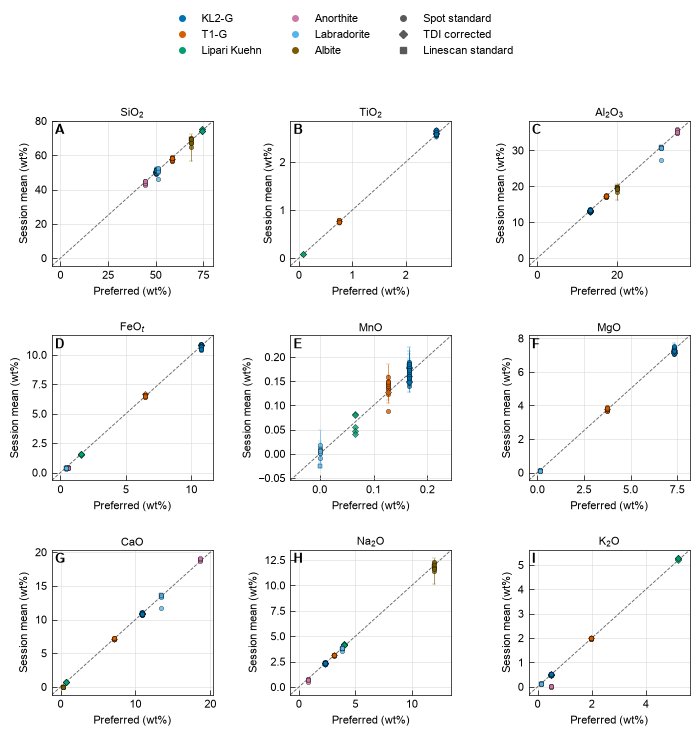

Final checks passed for 573 plotted session means.


In [5]:
STANDARD_COLORS = dict(zip(PREFERRED_SOURCE_TOKENS, ['#0072B2','#D55E00','#009E73','#CC79A7','#56B4E9','#7A5C00']))
TYPE_MARKERS = {'spot_standard':'o','TDI_corrected_standard':'D','line_scan_standard_point':'s'}
fig, axes = plt.subplots(3, 3, figsize=FIGURE_SIZE_IN)
for index,(ax,oxide) in enumerate(zip(axes.flat,OXIDES)):
    subset = comparison.loc[comparison['oxide'].eq(oxide)]
    for _,r in subset.iterrows():
        error = r['sd_wt_pct'] if pd.notna(r['sd_wt_pct']) else None
        ax.errorbar(r['preferred_wt_pct'],r['mean_wt_pct'],yerr=error,fmt=TYPE_MARKERS[r['analysis_type']],color=STANDARD_COLORS[r['reference_standard']],markersize=3.2,markeredgecolor='black',markeredgewidth=.28,elinewidth=.55,capsize=1.5,alpha=.8,zorder=3)
    lower = min(0,float(subset['preferred_wt_pct'].min()),float((subset['mean_wt_pct']-subset['sd_wt_pct'].fillna(0)).min()))
    upper = max(float(subset['preferred_wt_pct'].max()),float((subset['mean_wt_pct']+subset['sd_wt_pct'].fillna(0)).max()))
    pad=max(.025,.06*(upper-lower))
    limits=(lower-pad,upper+pad)
    ax.plot(limits,limits,'--',color='.4',lw=.65,zorder=1)
    ax.set(xlim=limits,ylim=limits,xlabel='Preferred (wt%)',ylabel='Session mean (wt%)')
    ax.set_title(OXIDE_LABELS[oxide], pad=3)
    ax.text(0.02, 0.98, chr(65 + index), transform=ax.transAxes, ha='left', va='top', fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold')
    ax.set_axisbelow(True)
    ax.grid(True, which='major', color='#D9D9D9', linewidth=.4, linestyle='-')
    ax.minorticks_off()
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(.5)
handles=[Line2D([],[],marker='o',ls='none',color=color,label=standard.replace('MAC_','').replace('STD2_','').replace('_',' '),markersize=4) for standard,color in STANDARD_COLORS.items()]
handles += [Line2D([],[],marker=marker,ls='none',color='.35',label=label,markersize=4) for label,marker in [('Spot standard','o'),('TDI corrected','D'),('Linescan standard','s')]]
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.995),ncol=3,frameon=False)
fig.subplots_adjust(left=.10,right=.98,bottom=.08,top=.84,wspace=.48,hspace=.48)
for suffix in ['pdf','svg','png']:
    path=OUTPUT_DIR/f'{FIGURE_STEM}.{suffix}'
    fig.savefig(path,**({'dpi':PNG_DPI} if suffix=='png' else {}))
    if not path.is_file() or path.stat().st_size == 0:
        raise IOError(f'Expected export was not created: {path}')
    print('Saved:',path)
display(fig)
plt.close(fig)
if comparison.loc[comparison.n.eq(1),'sd_wt_pct'].notna().any():
    raise ValueError('A single-measurement group should not have a sample SD.')
print(f'Final checks passed for {len(comparison)} plotted session means.')
